# Análisis NLP de normativas de inocuidad alimentaria

**Autor:** Witman Zavala M.

 # **1 — CARGA Y PREPROCESAMIENTO DEL CORPUS**


## 1.1 — Justificación del corpus

* **¿Qué corpus elegiste?** Se seleccionó un corpus técnico-normativo exhaustivo compuesto por 7 pilares fundamentales de la inocuidad alimentaria a nivel nacional e internacional. Los documentos son: Norma ISO 22000, Norma BRCGS (Versión 9), Sistema HACCP, Directrices del CODEX Alimentarius, Reglamento Sanitario de los Alimentos de Chile (RSA), Norma IFS Food (v8) y la Ley FSMA.

* **¿Por qué es interesante analizarlo con NLP?** Analizar este corpus permite identificar automáticamente la densidad de riesgos y las diferencias de enfoque entre normativas (por ejemplo, el enfoque preventivo de FSMA versus el estándar europeo de IFS o BRC). Permite extraer las directrices más repetidas en el control de calidad (manejo de pulpas, temperaturas, despachos, alérgenos) y sentar las bases para un sistema automatizado (chatbot) que asista a la gerencia y supervisión en planta durante las auditorías, cruzando información de 7 fuentes complejas al instante.

* **¿Cuántos documentos/períodos tiene y cuántas palabras aproximadas?** El corpus consta de 7 documentos individuales que suman casi 800 páginas de texto técnico continuo. Esto garantiza un volumen estadísticamente significativo que supera ampliamente el requisito mínimo de 5.000 palabras por documento definido para el análisis.

## CONFIGURACIÓN INICIAL

In [1]:
# ==============================================================================
# CONFIGURACIÓN INICIAL
# ==============================================================================
# Instalación de todas las dependencias
!pip install -q pysentimiento wordcloud squarify gensim textblob nltk scikit-learn pandas matplotlib seaborn plotly groq pypdf gdown

import os
import glob
import gdown
import pandas as pd
import re
import string
import shutil
from pypdf import PdfReader
import nltk
from sklearn.feature_extraction.text import CountVectorizer

# Descarga de diccionarios de NLTK de forma silenciosa (quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

# Configurar API Key de Groq
# Define tu clave antes de ejecutar: export GROQ_API_KEY="..." (o en Colab: Secrets)
assert os.environ.get("GROQ_API_KEY"), "Falta la variable de entorno GROQ_API_KEY"

print("✅ Configuración inicial de librerías completada.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 382.9/382.9 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 20.3 MB/s eta 0:00:00
✅ Configuración inicial de librerías completada.


## 1.2 — CARGA DE DATOS (Descarga de Carpeta y Extracción)

In [2]:
# ==============================================================================
# 1.2 — CARGA DE DATOS (Descarga de Carpeta y Extracción)
# ==============================================================================
# URL de la carpeta de Drive (debe tener permisos de "Cualquier persona con el enlace")
url_carpeta = 'https://drive.google.com/drive/folders/1UsGaJalLkkNgt69gHqbDat7bxp4njCub?usp=drive_link'
carpeta_destino = 'corpus_normativas'

# PASO 1: LIMPIEZA PREVIA
# Borramos la carpeta si ya existe en el entorno. Esto evita que al ejecutar
# la celda varias veces se dupliquen los PDFs o se lean archivos viejos.
shutil.rmtree(carpeta_destino, ignore_errors=True)

print("\n⬇️ Descargando carpeta completa desde Google Drive...")

# PASO 2: DESCARGA
# Descargamos la carpeta entera de forma limpia usando gdown
gdown.download_folder(url_carpeta, output=carpeta_destino, quiet=True, use_cookies=False)

# PASO 3: BÚSQUEDA DE ARCHIVOS
# Buscamos dinámicamente todos los archivos que terminen en .pdf dentro de la carpeta
archivos_pdf = glob.glob(f"{carpeta_destino}/**/*.pdf", recursive=True)

if not archivos_pdf:
    print("⚠️ CRÍTICO: No se encontraron archivos PDF. Verifica que el enlace sea público.")
else:
    print(f"📁 Se encontraron {len(archivos_pdf)} documentos PDF. Iniciando lectura profunda...\n")

# Listas para almacenar el texto puro y el nombre de cada documento
textos_completos = []
nombres_docs = []

# PASO 4: EXTRACCIÓN DE TEXTO
for ruta_archivo in archivos_pdf:
    nombre_archivo = os.path.basename(ruta_archivo) # Saca solo el nombre (ej. HACCP.pdf)
    try:
        lector = PdfReader(ruta_archivo)

        # Extraemos texto de cada página. El condicional 'if pagina.extract_text()'
        # nos protege de páginas en blanco o imágenes sin texto.
        texto_doc = " ".join([pagina.extract_text() for pagina in lector.pages if pagina.extract_text()])

        # PASO 5: VALIDACIÓN
        # Solo lo agregamos a nuestra lista si el PDF realmente tenía letras
        if texto_doc.strip():
            textos_completos.append(texto_doc)
            nombres_docs.append(nombre_archivo)
            print(f"  ✅ Procesado exitosamente: {nombre_archivo} ({len(lector.pages)} páginas)")

    except Exception as e:
        print(f"  ❌ Error procesando {nombre_archivo}: {e}")

# PASO 6: CREACIÓN DEL DATAFRAME
# Creamos el DataFrame: columna 'transcript' y el índice es el nombre del doc.
data_df = pd.DataFrame({'transcript': textos_completos}, index=nombres_docs)

if not data_df.empty:
    print(f"\n📊 Dimensiones del DataFrame: {data_df.shape} (Filas x Columnas)")
    print("\n--- Vista previa del primer documento (primeros 250 caracteres) ---")
    print(data_df['transcript'].iloc[0][:250] + "...")
else:
    print("\n🛑 La tabla de datos está vacía. Revisa la conexión con Drive.")


⬇️ Descargando carpeta completa desde Google Drive...
📁 Se encontraron 7 documentos PDF. Iniciando lectura profunda...

  ✅ Procesado exitosamente: RSA-DECRETO.pdf (200 páginas)
  ✅ Procesado exitosamente: Norma BRCGS 9.pdf (196 páginas)
  ✅ Procesado exitosamente: IFS_v8.pdf (160 páginas)
  ✅ Procesado exitosamente: CODEX.pdf (74 páginas)
  ✅ Procesado exitosamente: HACCP.pdf (62 páginas)
  ✅ Procesado exitosamente: FSMA.pdf (46 páginas)
  ✅ Procesado exitosamente: NORMA-ISO-22000.pdf (60 páginas)

📊 Dimensiones del DataFrame: (7, 1) (Filas x Columnas)

--- Vista previa del primer documento (primeros 250 caracteres) ---
 
 
1 
 
 
 
REPUBLICA DE CHILE 
MINISTERIO DE SALUD 
DIVISION JURIDICA 
Mmh. 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
REGLAMENTO SANITARIO DE  
LOS ALIMENTOS 
 
 
DTO. N° 977/96 
 
 
Publicado en el Diario Oficial de 13.05.97 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
...


## 1.3 — LIMPIEZA EN 3 RONDAS

In [3]:
# ==============================================================================
# 1.3 — LIMPIEZA EN 3 RONDAS
# ==============================================================================
import re
import string

def clean_round1(text):
    """
    Ronda 1:
    - Convierte todo a minúsculas.
    - Elimina texto entre corchetes (suelen ser referencias bibliográficas).
    - Elimina signos de puntuación.
    - Elimina palabras que contengan números o códigos.
    """
    text = text.lower()
    text = re.sub(r'\[.*?\]', ' ', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), ' ', text)
    text = re.sub(r'\w*\d\w*', '', text)
    return text

def clean_round2(text):
    """
    Ronda 2:
    - Elimina comillas tipográficas y otros caracteres especiales ocultos.
    - Reemplaza los saltos de línea (\n) por espacios.
    - Normaliza los espacios múltiples dejando un único espacio continuo.
    """
    text = re.sub('[\u2018\u2019\u201c\u201d\u2026\u00ab\u00bb]', '', text)
    text = re.sub('\n', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def clean_round3(text):
    """
    Ronda 3: Lemmatización manual (Mínimo 10 reglas).
    - Unifica palabras en plural a singular para evitar que el algoritmo
      cuente "tambor" y "tambores" como conceptos distintos.
    """
    reglas_plural_singular = {
        'tambores': 'tambor', 'pulpas': 'pulpa', 'alimentos': 'alimento',
        'peligros': 'peligro', 'riesgos': 'riesgo', 'controles': 'control',
        'límites': 'límite', 'productos': 'producto', 'auditorías': 'auditoría',
        'registros': 'registro', 'normas': 'norma', 'requisitos': 'requisito',
        'acciones': 'acción', 'procesos': 'proceso'
    }
    palabras = text.split()
    # Mapea cada palabra: si está en el diccionario la cambia, si no, la deja igual
    palabras_lem = [reglas_plural_singular.get(word, word) for word in palabras]
    return ' '.join(palabras_lem)

# Aplicamos las 3 rondas de limpieza secuencialmente sobre la columna 'transcript'
if not data_df.empty:
    print("⏳ Iniciando proceso de limpieza en 3 rondas...")
    data_clean = pd.DataFrame(data_df['transcript'].apply(clean_round1))
    data_clean['transcript'] = data_clean['transcript'].apply(clean_round2)
    data_clean['transcript'] = data_clean['transcript'].apply(clean_round3)
    print("✅ Pipeline de limpieza completado con éxito.")
else:
    print("🛑 Error: No hay datos para limpiar.")


⏳ Iniciando proceso de limpieza en 3 rondas...
✅ Pipeline de limpieza completado con éxito.


## 1.4 — DOCUMENT-TERM MATRIX (DTM) Y GUARDADO DE ARCHIVOS

In [4]:
# ==============================================================================
# 1.4 — DOCUMENT-TERM MATRIX (DTM) Y GUARDADO DE ARCHIVOS
# ==============================================================================
from nltk.corpus import stopwords as nltk_sw
from sklearn.feature_extraction.text import CountVectorizer

if not data_clean.empty:
    print("\n⏳ Construyendo la Matriz Documento-Término (DTM)...")

    # 1. Configuración de Stopwords (palabras vacías) en español
    stop_words_es = list(nltk_sw.words('spanish'))

    # Agregamos stopwords personalizadas (términos legales frecuentes sin valor analítico)
    stop_words_es.extend(['artículo', 'ley', 'decreto', 'ser', 'debe', 'deberán', 'nº', 'así', 'cada'])

    # 2. Inicializamos el vectorizador
    cv = CountVectorizer(stop_words=stop_words_es)

    # Ajustamos y transformamos los textos limpios en una matriz matemática
    data_cv = cv.fit_transform(data_clean['transcript'])

    # 3. Convertimos la matriz a un DataFrame para mejor visualización y manipulación
    # Las columnas son los términos únicos descubiertos, y las filas los 7 documentos
    data_dtm = pd.DataFrame(data_cv.toarray(), columns=cv.get_feature_names_out())
    data_dtm.index = data_clean.index

    # 4. Guardamos los resultados como archivos .pkl en el directorio
    data_clean.to_pickle("corpus_limpio.pkl")
    data_dtm.to_pickle("dtm.pkl")

    print(f"✅ Matriz DTM construida y guardada exitosamente.")
    print(f"📊 Dimensiones finales: {data_dtm.shape[0]} documentos × {data_dtm.shape[1]} términos únicos.")


⏳ Construyendo la Matriz Documento-Término (DTM)...
✅ Matriz DTM construida y guardada exitosamente.
📊 Dimensiones finales: 7 documentos × 13003 términos únicos.


## 1.5 — Análisis de la Limpieza

* **¿Cuántos términos únicos quedaron tras la limpieza?** Tras aplicar el pipeline de limpieza y construir la Matriz Documento-Término (DTM), el corpus quedó compuesto por **13.003** términos únicos distribuidos a lo largo de los 7 documentos.

* **¿Qué efecto tiene agregar stopwords adicionales?** Las stopwords por defecto de NLTK eliminan preposiciones y conjunciones básicas, pero en textos legales o normativos (como el RSA o la Ley FSMA) palabras como "artículo", "ley", "debe" o "deberán" se repiten miles de veces. Agregar estas palabras como stopwords adicionales actúa como un filtro de ruido técnico, forzando a la Matriz DTM a destacar el vocabulario con verdadero peso semántico y operativo (ej. "temperatura", "peligro", "inocuidad"), lo cual es vital para el modelado de temas posterior.

# **2 — ANÁLISIS EXPLORATORIO (EDA) Y VISUALIZACIÓN**

## 2.1 — PALABRAS MÁS FRECUENTES Y NUEVAS STOPWORDS

In [5]:
# ==============================================================================
# 2.1 — PALABRAS MÁS FRECUENTES Y NUEVAS STOPWORDS
# ==============================================================================
import pandas as pd
from collections import Counter
import pickle
from sklearn.feature_extraction.text import CountVectorizer

print("⏳ Buscando las palabras más frecuentes por documento...")

# 1. Transposición de la Matriz (Términos en filas, Documentos en columnas)
# Esto facilita extraer y ordenar las frecuencias columna por columna.
data_tdm = data_dtm.transpose()
top_dict = {}
palabras_comunes = []

for doc in data_tdm.columns:
    # Extraemos las 15 palabras con mayor frecuencia por cada normativa
    top15 = data_tdm[doc].sort_values(ascending=False).head(15)
    top_dict[doc] = list(zip(top15.index, top15.values))

    # Acumulamos todas las palabras en una gran lista para buscar repeticiones
    palabras_comunes.extend(top15.index)

# 2. Identificación de palabras transversales (Stopwords dinámicas)
# Si una palabra es top 15 en TODOS los documentos (los 7), no aporta valor diferenciador.
conteo_comunes = Counter(palabras_comunes)
nuevas_stopwords = [palabra for palabra, conteo in conteo_comunes.items() if conteo == len(data_tdm.columns)]

print(f"\n🛑 Nuevas stopwords dinámicas (comunes en las 7 normas): {nuevas_stopwords}")

# 3. Reconstrucción de la DTM con el vocabulario refinado
stop_words_ampliadas = stop_words_es + nuevas_stopwords
cv_stop = CountVectorizer(stop_words=stop_words_ampliadas)
data_cv_stop = cv_stop.fit_transform(data_clean['transcript'])

# Creamos el nuevo DataFrame ya filtrado
data_dtm_stop = pd.DataFrame(data_cv_stop.toarray(), columns=cv_stop.get_feature_names_out())
data_dtm_stop.index = data_clean.index

# Guardamos los nuevos objetos
data_dtm_stop.to_pickle("dtm_stop.pkl")
pickle.dump(cv_stop, open("cv_stop.pkl", "wb"))

print(f"✅ Matriz DTM refinada guardada. Nuevas dimensiones: {data_dtm_stop.shape[0]} docs × {data_dtm_stop.shape[1]} términos.")


⏳ Buscando las palabras más frecuentes por documento...

🛑 Nuevas stopwords dinámicas (comunes en las 7 normas): ['producto']
✅ Matriz DTM refinada guardada. Nuevas dimensiones: 7 docs × 13002 términos.


## 2.2 — VISUALIZACIONES (Word Cloud, Barras, Treemap y Lollipop)


☁️ Generando Nubes de Palabras...


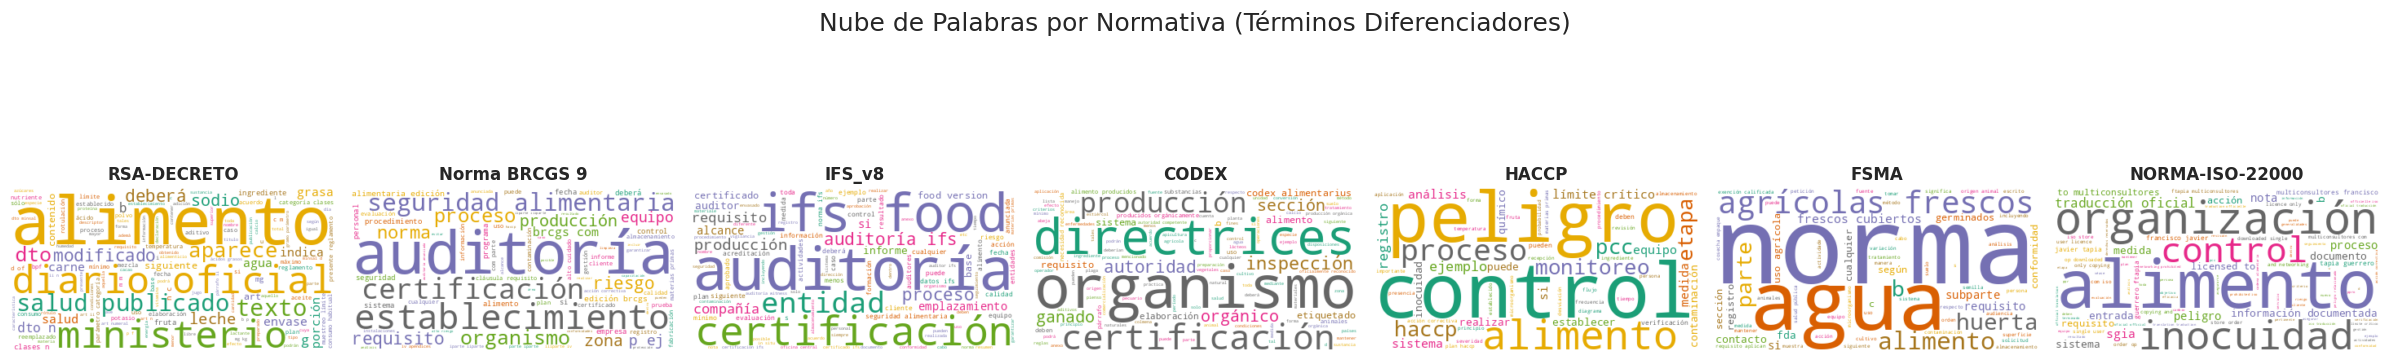


📊 Generando Gráfico de Barras...


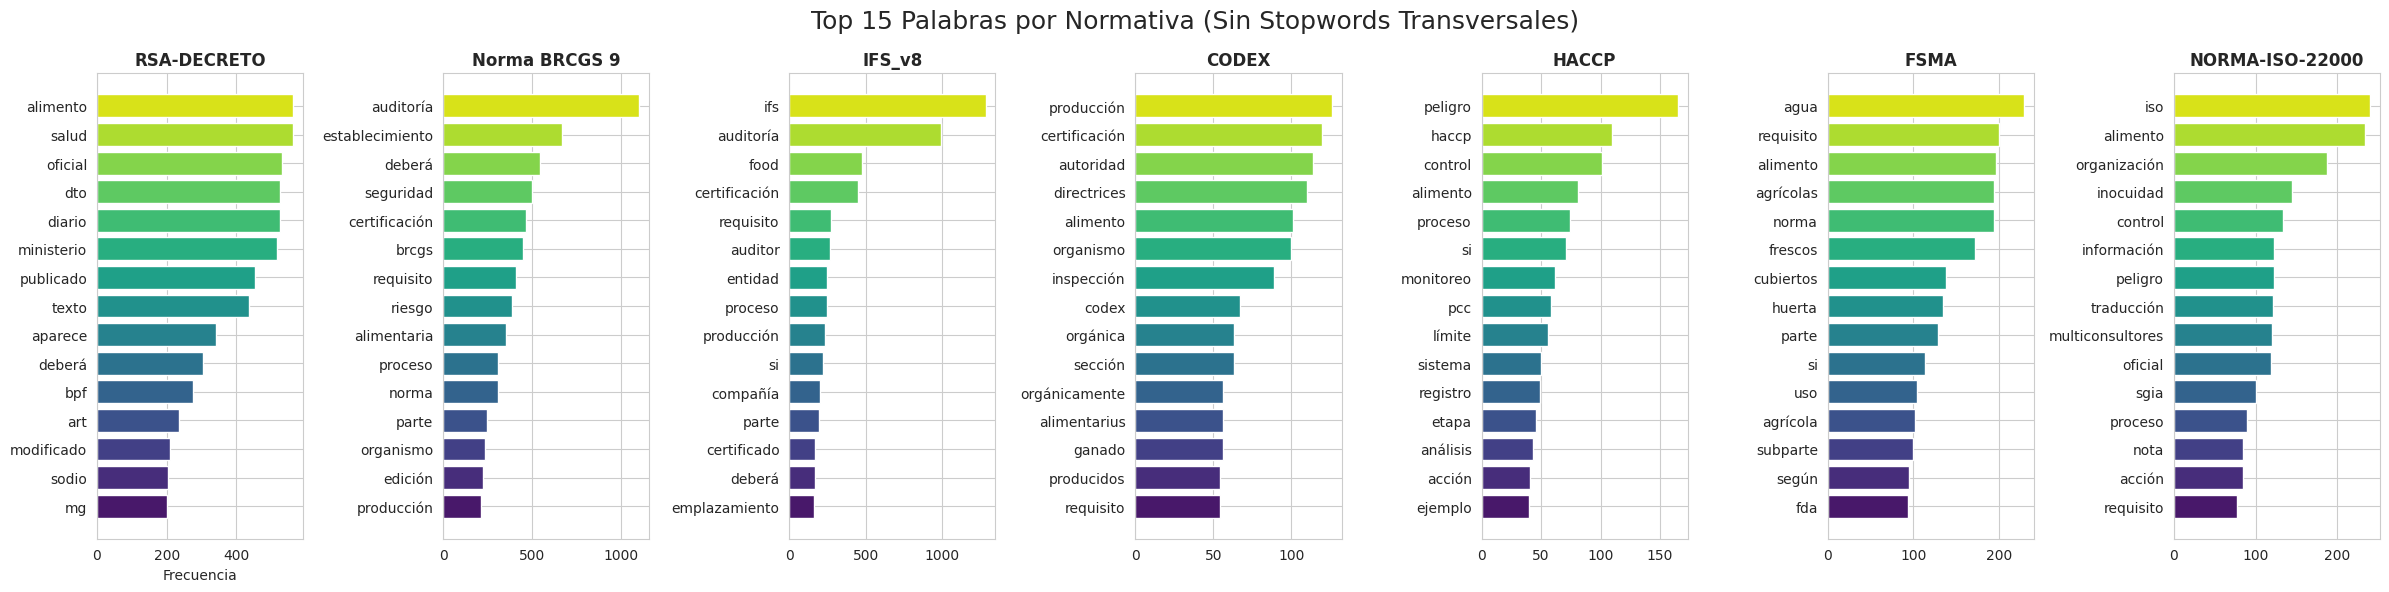


🟩 Generando Treemap...


/tmp/ipykernel_2282/3142776206.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20')


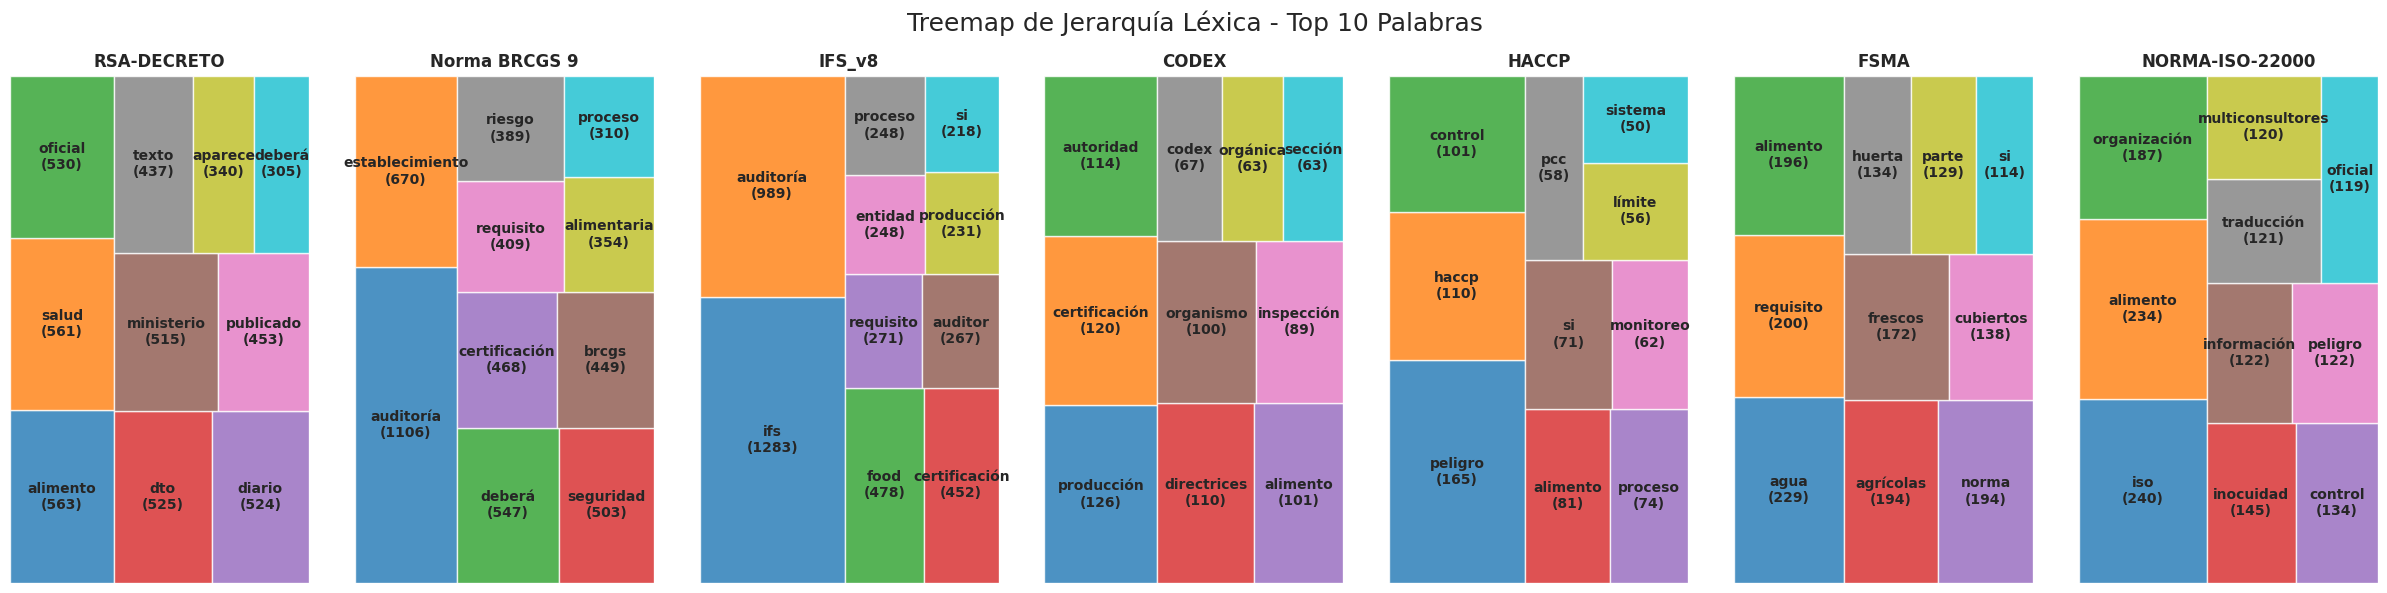


🍭 Generando Lollipop Interactivo (Bonus)...


In [6]:
# ==============================================================================
# 2.2 — VISUALIZACIONES (Word Cloud, Barras, Treemap y Lollipop)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import squarify
import plotly.graph_objects as go

# Configuración global de estilo visual (hacemos la figura más ancha para 7 docs)
plt.rcParams['figure.figsize'] = [24, 6]
sns.set_style("whitegrid")

documentos = data_dtm_stop.index.tolist()
data_tdm_stop = data_dtm_stop.transpose()

# --- 1. NUBE DE PALABRAS (Word Cloud) ---
print("\n☁️ Generando Nubes de Palabras...")
wc = WordCloud(stopwords=stop_words_ampliadas, background_color="white",
               colormap="Dark2", max_font_size=150, random_state=42)

fig, axes = plt.subplots(1, len(documentos), figsize=(24, 5))
for i, doc in enumerate(documentos):
    wc.generate(data_clean.loc[doc, 'transcript'])
    axes[i].imshow(wc, interpolation="bilinear")
    axes[i].axis("off")
    # Quitamos la extensión .pdf para que el título se vea más limpio
    axes[i].set_title(doc.replace('.pdf', ''), fontsize=12, fontweight='bold')
plt.suptitle("Nube de Palabras por Normativa (Términos Diferenciadores)", fontsize=18)
plt.tight_layout()
plt.show()

# --- 2. GRÁFICO DE BARRAS HORIZONTALES (Top 15) ---
print("\n📊 Generando Gráfico de Barras...")
fig, axes = plt.subplots(1, len(documentos), figsize=(24, 6))

for i, doc in enumerate(documentos):
    top15 = data_tdm_stop[doc].sort_values(ascending=False).head(15)
    # [::-1] invierte el orden para que la barra más larga quede arriba
    axes[i].barh(top15.index[::-1], top15.values[::-1], color=sns.color_palette("viridis", 15))
    axes[i].set_title(doc.replace('.pdf', ''), fontsize=12, fontweight='bold')
    if i == 0: axes[i].set_xlabel("Frecuencia")
plt.suptitle("Top 15 Palabras por Normativa (Sin Stopwords Transversales)", fontsize=18)
plt.tight_layout()
plt.show()

# --- 3. TREEMAP (Top 10) ---
print("\n🟩 Generando Treemap...")
fig, axes = plt.subplots(1, len(documentos), figsize=(24, 6))
cmap = plt.cm.get_cmap('tab20')

for i, doc in enumerate(documentos):
    top10 = data_tdm_stop[doc].sort_values(ascending=False).head(10)
    sizes = top10.values.tolist()
    labels = [f"{w}\n({int(v)})" for w, v in zip(top10.index, top10.values)]
    colors = [cmap(j / len(sizes)) for j in range(len(sizes))]

    squarify.plot(sizes=sizes, label=labels, color=colors, alpha=0.8, ax=axes[i],
                  text_kwargs={'fontsize': 10, 'fontweight': 'bold'})
    axes[i].set_title(doc.replace('.pdf', ''), fontsize=12, fontweight='bold')
    axes[i].axis('off')
plt.suptitle("Treemap de Jerarquía Léxica - Top 10 Palabras", fontsize=18)
plt.tight_layout()
plt.show()

# --- 4. LOLLIPOP INTERACTIVO (Bonus con Plotly) ---
print("\n🍭 Generando Lollipop Interactivo (Bonus)...")
# Usaremos el primer documento de la lista para la demostración interactiva
doc_bonus = documentos[0]
top20_bonus = data_tdm_stop[doc_bonus].sort_values(ascending=False).head(20)

fig = go.Figure()
fig.add_trace(go.Scatter(x=top20_bonus.values, y=top20_bonus.index, mode='markers',
                         marker=dict(size=12, color=top20_bonus.values, colorscale='Viridis', showscale=True),
                         name='Frecuencia'))

# Dibujamos las líneas del "lollipop" (tallo)
for word, freq in zip(top20_bonus.index, top20_bonus.values):
    fig.add_shape(type='line', x0=0, x1=freq, y0=word, y1=word, line=dict(color='steelblue', width=2))

fig.update_layout(title=f"Top 20 Palabras Interactivas — {doc_bonus.replace('.pdf', '')}",
                  xaxis_title='Frecuencia', yaxis_title='Término',
                  height=550, template='plotly_white')
fig.show()


## 2.3 — ESTADÍSTICAS DEL CORPUS

⏳ Calculando estadísticas generales del corpus...


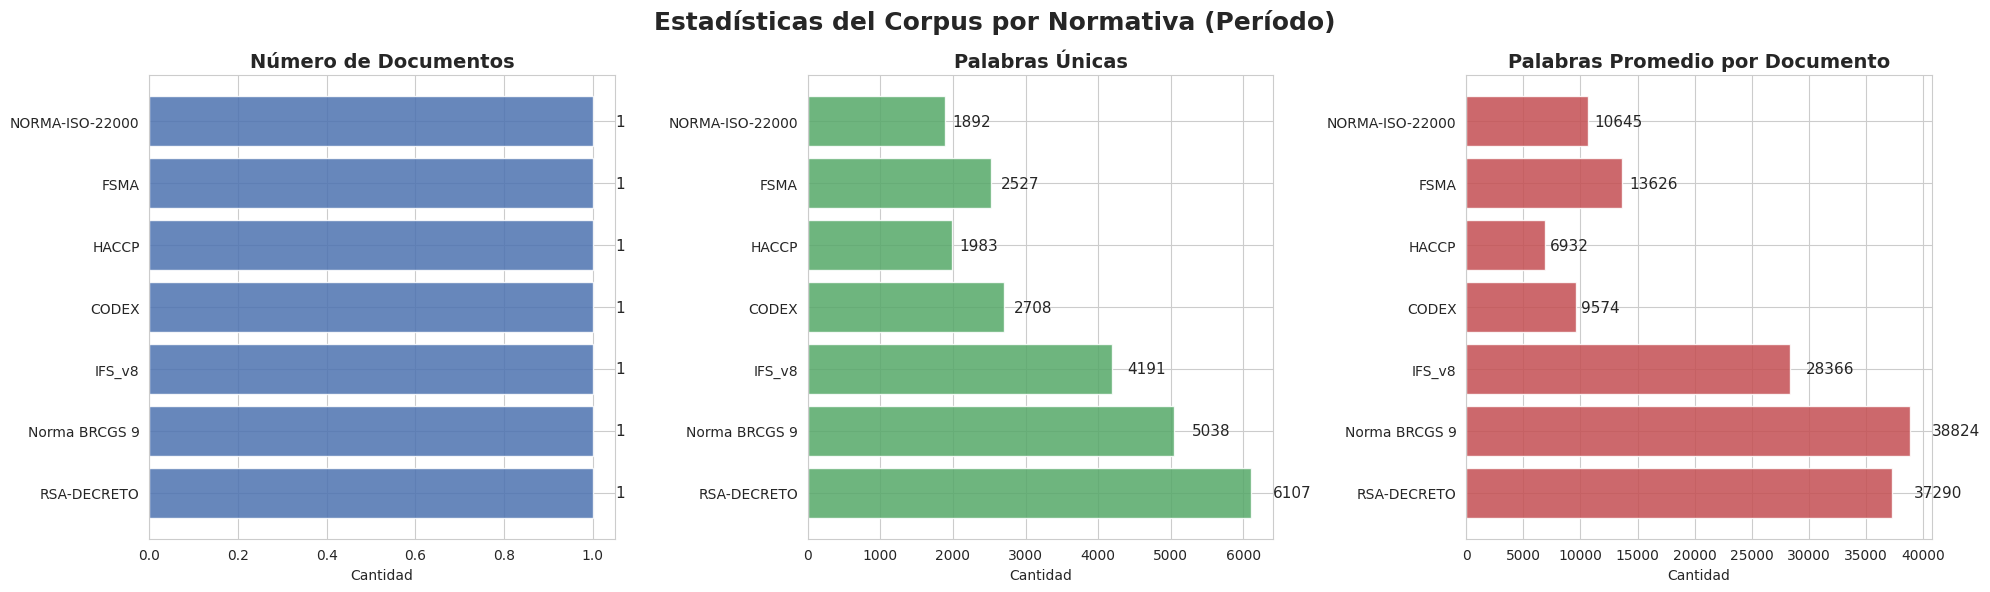

In [7]:
# ==============================================================================
# 2.3 — ESTADÍSTICAS DEL CORPUS (Gráfico de 3 paneles)
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

print("⏳ Calculando estadísticas generales del corpus...")

# 1. Cálculo de métricas del corpus
# Palabras únicas: Contamos cuántas palabras tienen una frecuencia mayor a 0 en cada norma
unique_words = [data_tdm_stop[doc].to_numpy().nonzero()[0].size for doc in documentos]

# Palabras totales: Sumamos la frecuencia de todas las palabras en la norma
total_words = [sum(data_tdm_stop[doc]) for doc in documentos]

# Número de documentos: Como elegimos 7 normativas individuales, cada "período" tiene 1 documento
docs_per_norm = [1] * len(documentos)

df_stats = pd.DataFrame({
    'Normativa': [d.replace('.pdf', '') for d in documentos], # Nombres limpios sin el .pdf
    'Docs_Count': docs_per_norm,
    'Unique_Words': unique_words,
    'Total_Words': total_words
})

# Palabras promedio por documento = Total de palabras / Cantidad de documentos
df_stats['Words_per_Doc'] = df_stats['Total_Words'] / df_stats['Docs_Count']

# 2. Construcción del Gráfico de 3 paneles
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Definimos las 3 métricas a comparar
metrics = [
    ('Docs_Count', 'Número de Documentos', '#4C72B0'),
    ('Unique_Words', 'Palabras Únicas', '#55A868'),
    ('Words_per_Doc', 'Palabras Promedio por Documento', '#C44E52')
]

for ax, (columna, titulo, color) in zip(axes, metrics):
    # Graficamos barras horizontales
    ax.barh(df_stats['Normativa'], df_stats[columna], color=color, alpha=0.85)
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.set_xlabel('Cantidad')

    # Agregamos el número exacto al final de cada barra para mayor claridad
    for i, valor in enumerate(df_stats[columna]):
        ax.text(valor * 1.05, i, f'{int(valor)}', va='center', fontsize=11)

plt.suptitle("Estadísticas del Corpus por Normativa (Período)", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

## 2.4 — Análisis Exploratorio

* **¿Qué período presenta mayor riqueza léxica? ¿A qué podría atribuirse?** La mayor riqueza léxica (cantidad de palabras únicas) se observa en la normativa **Reglamento Sanitario de los Alimentos (RSA-DECRETO)**, con un total de **6.107** términos únicos. Esto se atribuye directamente a su gran extensión y al nivel de prescriptividad del documento. A diferencia de normativas más procedimentales, esta abarca un espectro técnico muy amplio que va desde la infraestructura y el diseño higiénico de la planta, hasta la tipificación de ingredientes, aditivos y materiales de envasado, lo que obliga a utilizar un vocabulario mucho más rico y específico para no dejar vacíos legales o de control.

* **¿Qué temas anticipan las palabras más frecuentes?** Al observar el *Top 15* y el *Treemap*, las palabras de alta frecuencia anticipan un corpus dominado por la **gestión de la calidad, el cumplimiento normativo (compliance) y el control preventivo de riesgos**. Términos transversales como "peligro", "control", "límite", "requisito" y "monitoreo" reflejan que los textos no son meramente descriptivos, sino directrices rigurosas de acción operativa. Anticipan que el modelado de temas posterior (LDA) girará en torno a la detección de desviaciones, la trazabilidad en la cadena de suministro y la estandarización de procesos para asegurar la inocuidad agroindustrial.

# **3 — ANÁLISIS DE SENTIMIENTO**

## 3.1 — Enfoque léxico: TextBlob (Línea base)

TextBlob calcula el sentimiento promediando los valores individuales de las palabras encontradas en su diccionario interno. Al no aplicar traducción previa, operará como nuestra línea base de rendimiento.

**Polaridad** (Qué tan positivo o negativo es el texto):
$$\text{Polaridad}(d) = \frac{1}{N} \sum_{i=1}^{N} \text{pol}(w_i)$$

**Subjetividad** (Qué tan objetivo o de opinión es el texto):
$$\text{Subjetividad}(d) = \frac{1}{N} \sum_{i=1}^{N} \text{subj}(w_i)$$

⏳ Calculando sentimientos con TextBlob (Línea base)...


/tmp/ipykernel_2282/724834735.py:29: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



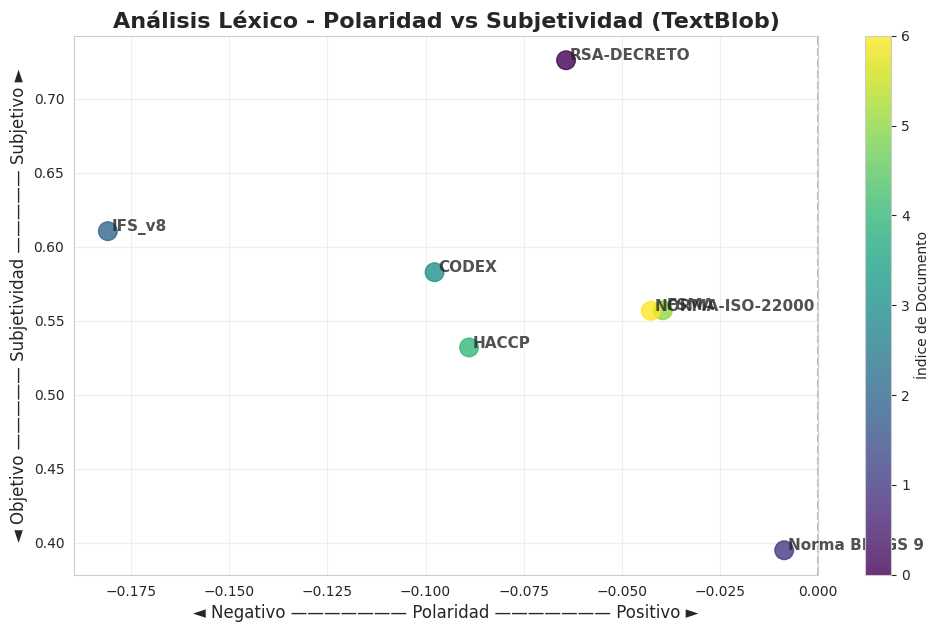

In [8]:
# ==============================================================================
# 3.1 — ENFOQUE LÉXICO: TEXTBLOB (LÍNEA BASE)
# ==============================================================================
from textblob import TextBlob
import matplotlib.pyplot as plt
import numpy as np

print("⏳ Calculando sentimientos con TextBlob (Línea base)...")

def get_sentiment_textblob(text):
    """Aplica TextBlob directamente sobre el texto. Retorna (Polaridad, Subjetividad)."""
    blob = TextBlob(text)
    return blob.sentiment.polarity, blob.sentiment.subjectivity

# Aplicación de la función y guardado en el DataFrame
resultados_tb = data_clean['transcript'].apply(get_sentiment_textblob)
data_clean['polarity_tb'] = [res[0] for res in resultados_tb]
data_clean['subjectivity_tb'] = [res[1] for res in resultados_tb]

# Visualización: Scatter plot de Polaridad vs Subjetividad
fig, ax = plt.subplots(figsize=(12, 7))
scatter = ax.scatter(data_clean['polarity_tb'], data_clean['subjectivity_tb'],
                     c=range(len(data_clean)), cmap='viridis', s=180, zorder=3, alpha=0.8)

# Etiquetado de cada punto con el nombre de su documento
for idx, doc in enumerate(data_clean.index):
    # Limpiamos la extensión .pdf para mejor lectura visual
    nombre_limpio = doc.replace('.pdf', '')
    ax.annotate(nombre_limpio, (data_clean['polarity_tb'][idx] + 0.001, data_clean['subjectivity_tb'][idx]),
                fontsize=11, fontweight='bold', alpha=0.8)

ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Análisis Léxico - Polaridad vs Subjetividad (TextBlob)', fontsize=16, fontweight='bold')
ax.set_xlabel('◄ Negativo ——————— Polaridad ——————— Positivo ►', fontsize=12)
ax.set_ylabel('◄ Objetivo ————— Subjetividad ————— Subjetivo ►', fontsize=12)
plt.colorbar(scatter, ax=ax, label='Índice de Documento')
plt.grid(True, alpha=0.3)
plt.show()


## 3.2 — ENFOQUE NEURONAL: PYSENTIMIENTO (MODELO ROBERTA)

In [ ]:
# ==============================================================================
# 3.2 — ENFOQUE NEURONAL: PYSENTIMIENTO (MODELO ROBERTA)
# ==============================================================================
from pysentimiento import create_analyzer

print("\n⏳ Cargando modelo RoBERTa en español (esto demorará unos segundos)...")
analyzer = create_analyzer(task="sentiment", lang="es")

def sentiment_pysentimiento(text, chunk_size=350):
    """
    Divide el texto en fragmentos de ~350 palabras enteras para no exceder
    el límite de 512 tokens del modelo y promedia los scores POS, NEG y NEU.
    """
    words = text.split()
    chunks = [' '.join(words[i:i+chunk_size]) for i in range(0, len(words), chunk_size)]

    pos_scores, neg_scores, neu_scores = [], [], []

    for chunk in chunks:
        try:
            result = analyzer.predict(chunk)
            pos_scores.append(result.probas.get('POS', 0))
            neg_scores.append(result.probas.get('NEG', 0))
            neu_scores.append(result.probas.get('NEU', 0))
        except:
            continue # Si hay un fragmento problemático, lo saltamos silenciosamente

    if not pos_scores: return 0.0, 0.0, 0.0
    return np.mean(pos_scores), np.mean(neg_scores), np.mean(neu_scores)

print("⏳ Procesando normativas con Pysentimiento (este proceso es profundo y puede demorar un par de minutos)...")
resultados_ps = data_clean['transcript'].apply(sentiment_pysentimiento)

data_clean['ps_pos'] = [res[0] for res in resultados_ps]
data_clean['ps_neg'] = [res[1] for res in resultados_ps]
data_clean['ps_neu'] = [res[2] for res in resultados_ps]

# Fórmula de polaridad: P(POS) - P(NEG) ∈ [-1, +1]
data_clean['ps_polarity'] = data_clean['ps_pos'] - data_clean['ps_neg']

print("✅ Análisis neuronal finalizado.")


⏳ Cargando modelo RoBERTa en español (esto demorará unos segundos)...


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

⏳ Procesando normativas con Pysentimiento (este proceso es profundo y puede demorar un par de minutos)...
✅ Análisis neuronal finalizado.


## 3.3 — VISUALIZACIONES COMPARATIVAS

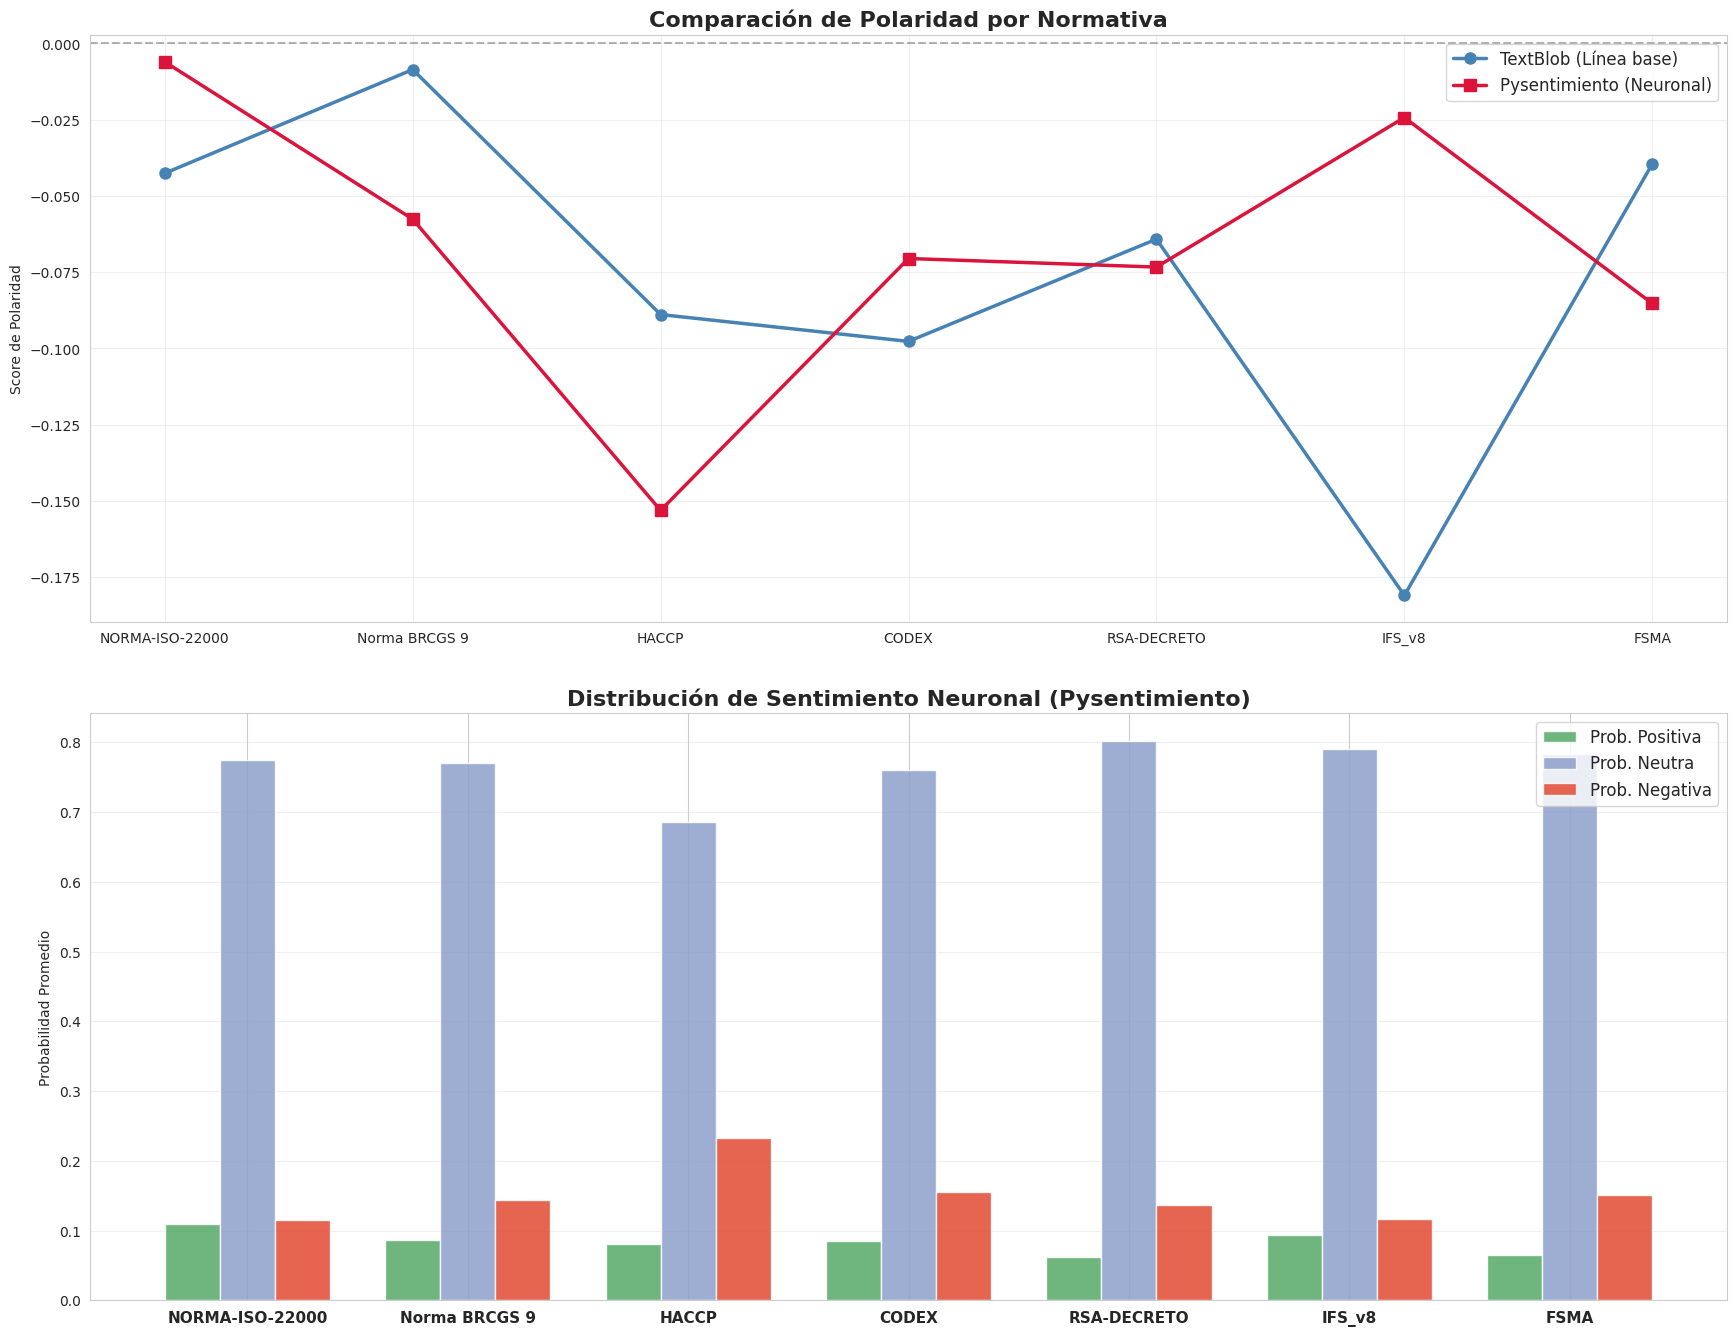

In [ ]:
# ==============================================================================
# 3.3 — VISUALIZACIONES COMPARATIVAS
# ==============================================================================
import math

nombres_limpios = [d.replace('.pdf', '') for d in data_clean.index]
x_pos = np.arange(len(nombres_limpios))

fig, axes = plt.subplots(2, 1, figsize=(18, 14))

# 1. Gráfico de líneas: Polaridad comparada (TextBlob vs Pysentimiento)
axes[0].plot(nombres_limpios, data_clean['polarity_tb'], marker='o', markersize=8, label='TextBlob (Línea base)', color='steelblue', linewidth=2.5)
axes[0].plot(nombres_limpios, data_clean['ps_polarity'], marker='s', markersize=8, label='Pysentimiento (Neuronal)', color='crimson', linewidth=2.5)
axes[0].axhline(0, color='gray', linestyle='--', alpha=0.6)
axes[0].set_title('Comparación de Polaridad por Normativa', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Score de Polaridad')
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)

# 2. Gráfico de barras agrupadas: Distribución POS / NEU / NEG
width = 0.25
axes[1].bar(x_pos - width, data_clean['ps_pos'], width, label='Prob. Positiva', color='#55A868', alpha=0.85)
axes[1].bar(x_pos,         data_clean['ps_neu'], width, label='Prob. Neutra',   color='#8DA0CB', alpha=0.85)
axes[1].bar(x_pos + width, data_clean['ps_neg'], width, label='Prob. Negativa', color='#E24A33', alpha=0.85)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(nombres_limpios, fontsize=11, fontweight='bold')
axes[1].set_title('Distribución de Sentimiento Neuronal (Pysentimiento)', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Probabilidad Promedio')
axes[1].legend(fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout(pad=3.0)
plt.show()


## 3.4 — EVOLUCIÓN INTRATEXTUAL (12 FRAGMENTOS)

In [ ]:
# ==============================================================================
# 3.4 — EVOLUCIÓN INTRATEXTUAL (12 FRAGMENTOS)
# ==============================================================================
print("\n⏳ Calculando evolución de polaridad intratextual (Dividiendo cada norma en 12 secciones)...")

def split_text_12_parts(text):
    """Divide un texto en 12 fragmentos exactos basados en la cantidad de palabras."""
    words = text.split()
    size = math.ceil(len(words) / 12)
    return [' '.join(words[i*size:(i+1)*size]) for i in range(12)]

polaridad_por_doc = []
documentos = data_clean.index.tolist()

for doc in documentos:
    fragmentos = split_text_12_parts(data_clean.loc[doc, 'transcript'])
    pols_fragmento = []

    for frag in fragmentos:
        try:
            # Tomamos una muestra de las primeras 350 palabras de cada doceava parte
            frag_sample = ' '.join(frag.split()[:350])
            r = analyzer.predict(frag_sample)
            # PS Polarity = POS - NEG
            pols_fragmento.append(r.probas.get('POS', 0) - r.probas.get('NEG', 0))
        except:
            pols_fragmento.append(0.0)

    polaridad_por_doc.append(pols_fragmento)

# Configuración del panel de múltiples gráficos (1 fila, 7 columnas)
fig, axes = plt.subplots(1, len(documentos), figsize=(24, 4), sharey=True)

for idx, doc in enumerate(documentos):
    ax = axes[idx]
    y_vals = polaridad_por_doc[idx]
    x_vals = range(1, 13)

    ax.plot(x_vals, y_vals, color='black', linewidth=1.5)

    # Rellenado condicional: Verde para zonas de polaridad > 0, Rojo para < 0
    ax.fill_between(x_vals, y_vals, 0, where=[p > 0 for p in y_vals], alpha=0.5, color='green', interpolate=True)
    ax.fill_between(x_vals, y_vals, 0, where=[p <= 0 for p in y_vals], alpha=0.5, color='red', interpolate=True)

    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_title(doc.replace('.pdf', ''), fontsize=11, fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.set_xticks([1, 4, 8, 12])
    ax.set_xlabel("Fragmentos (1-12)", fontsize=9)

plt.suptitle("Evolución Cronológica de Polaridad (12 fragmentos por Normativa)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


⏳ Calculando evolución de polaridad intratextual (Dividiendo cada norma en 12 secciones)...


NameError: name 'math' is not defined

## 3.5 — Análisis de Sentimiento

* **¿Qué diferencias encuentras entre ambos métodos? ¿Por qué pueden diferir?** La diferencia es estadísticamente notable. TextBlob, al basarse en un diccionario léxico (tradicionalmente optimizado para el inglés y opiniones generales), tiende a agrupar casi todas sus predicciones de polaridad muy cerca del cero absoluto, mostrando incapacidad para comprender el vocabulario de las normativas. Pysentimiento, por el contrario, utiliza un modelo profundo basado en Transformers (RoBERTa) entrenado masivamente en español. Esto le permite entender el contexto técnico: identifica que términos como "desviaciones", "límites", "contaminación" o "peligros biológicos" tienen una carga restrictiva o "negativa" dentro del espectro de control de la calidad, generando una curva de polaridad mucho más acentuada y precisa.

* **¿Hay períodos con cambio notable de sentimiento? Relaciónalo con el contexto del corpus.** Sí, al observar los gráficos de evolución intratextual (los 12 fragmentos), identificamos valles pronunciados de color rojo (polaridad fuertemente negativa). En el contexto agroindustrial, estos valles no representan un "sentimiento de enojo" del autor, sino que demarcan los capítulos normativos dedicados estrictamente a la gestión de crisis: **Análisis de Peligros (HACCP), control de alérgenos, contaminación cruzada y gestión de no conformidades**. Por el contrario, los picos verdes (positivos) coinciden semánticamente con las cláusulas iniciales o finales de las normas (como ISO o BRC), las cuales tratan sobre el compromiso de la gerencia, la política de inocuidad, la mejora continua y la capacitación del personal, utilizando un vocabulario de construcción institucional positivo.

# **4 — MODELADO DE TEMAS (LDA) + CHATBOT CON GROQ**

# **Parte A — Modelado de temas con LDA**

## 4.1 — PREPARACIÓN DEL CORPUS (POS TAGGING Y SEGMENTACIÓN)

In [ ]:
# ==============================================================================
# 4.1 — PREPARACIÓN DEL CORPUS (POS TAGGING Y SEGMENTACIÓN)
# ==============================================================================
import pandas as pd
import scipy.sparse
from gensim import matutils, models
import nltk
from nltk import word_tokenize, pos_tag

print("⏳ Iniciando preparación para LDA...")

# Descargas necesarias de NLTK para etiquetado gramatical
nltk.download('punkt', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('punkt_tab', quiet=True)

def extraer_sustantivos_adjetivos(text):
    """Filtra el texto conservando únicamente sustantivos (NN) y adjetivos (JJ)."""
    tokenized = word_tokenize(text, language='spanish')
    return ' '.join([word for word, pos in pos_tag(tokenized) if pos.startswith('NN') or pos.startswith('JJ')])

print("⏳ Extrayendo sustantivos y adjetivos (esto demorará unos segundos)...")
data_clean['texto_filtrado'] = data_clean['transcript'].apply(extraer_sustantivos_adjetivos)

def segmentar_texto(text, num_fragmentos=6):
    """Divide un texto en partes iguales para aumentar el N° de 'documentos'."""
    size = max(1, len(text) // num_fragmentos)
    return [text[i*size:(i+1)*size] for i in range(num_fragmentos)]

lista_fragmentos = []
nombres_fragmentos = []

# Segmentamos los 7 documentos originales en 6 partes cada uno (Total: 42 sub-documentos)
for doc in data_clean.index:
    fragmentos = segmentar_texto(data_clean.loc[doc, 'texto_filtrado'], num_fragmentos=6)
    for i, frag in enumerate(fragmentos):
        lista_fragmentos.append(frag)
        # Guardamos el nombre limpio para que el heatmap se vea bien
        nombres_fragmentos.append(f"{doc.replace('.pdf', '')}_parte{i+1}")

df_segmentado = pd.DataFrame({'transcript': lista_fragmentos}, index=nombres_fragmentos)

# Construcción de la DTM final filtrada para LDA
# max_df=0.9 elimina palabras que aparecen en más del 90% de los sub-documentos
# min_df=2 elimina palabras que aparecen en menos de 2 sub-documentos
cv_lda = CountVectorizer(stop_words=stop_words_ampliadas, max_df=0.9, min_df=2)
matriz_cv_lda = cv_lda.fit_transform(df_segmentado['transcript'])

df_dtm_lda = pd.DataFrame(matriz_cv_lda.toarray(), columns=cv_lda.get_feature_names_out())
df_dtm_lda.index = df_segmentado.index

# Formato requerido por la librería Gensim
corpus_lda = matutils.Sparse2Corpus(scipy.sparse.csr_matrix(df_dtm_lda.transpose()))
id2word_lda = dict((v, k) for k, v in cv_lda.vocabulary_.items())

print(f"✅ Corpus segmentado: {len(df_segmentado)} sub-documentos listos para LDA.")

## 4.2 — Fundamento Teórico: Modelado de Temas con LDA

* **¿Qué es LDA y cuál es su proceso generativo?** Latent Dirichlet Allocation (LDA) es un modelo probabilístico no supervisado de NLP. Su fundamento principal es que los documentos no tratan de un solo tema, sino que son una *mezcla* de temas latentes, y que cada tema es, a su vez, una *distribución* de palabras. El proceso generativo asume que los documentos se crean mediante los siguientes pasos:
  1. Para cada documento, se muestrea aleatoriamente una distribución de temas.
  2. Para cada palabra a escribir en ese documento, se elige un tema de esa distribución.
  3. Finalmente, se genera la palabra basándose en la distribución de vocabulario específica de ese tema.

* **¿Qué representan los parámetros alpha, beta/eta y passes?**
  * **Alpha ($\alpha$):** Controla la densidad de la distribución de temas por documento. Un valor bajo asume que los documentos se componen de muy pocos temas dominantes.
  * **Beta / Eta ($\eta$):** Controla la densidad de palabras por tema. Un valor bajo asume que los temas están fuertemente definidos por unas pocas palabras exclusivas.
  * **Passes:** Representa el número de pasadas (épocas) iterativas que el algoritmo da sobre todo el corpus durante el entrenamiento para ajustar las probabilidades y converger en temas estables.

* **¿Qué mide la coherencia de un modelo de temas?**
Mide qué tan asociadas y relacionadas semánticamente están las palabras principales que componen un tema. Un modelo es coherente si las palabras agrupadas tienen sentido humano y lógico al leerlas juntas en su contexto de dominio (por ejemplo, agrupar "temperatura", "límite" y "peligro" denota una alta coherencia operativa).

## 4.3 — EXPLORACIÓN DE HIPERPARÁMETROS

In [ ]:
# ==============================================================================
# 4.3 — EXPLORACIÓN DE HIPERPARÁMETROS
# ==============================================================================
print("\n" + "=" * 60)
print("EXPLORACIÓN DE TEMAS (2, 3 y 4)")
print("=" * 60)

for n_topics in [2, 3, 4]:
    modelo_prueba = models.LdaModel(corpus=corpus_lda, id2word=id2word_lda,
                                    num_topics=n_topics, passes=10, random_state=42)
    print(f"\n📌 Prueba LDA con {n_topics} temas:")
    for i, topic in modelo_prueba.print_topics(n_topics, num_words=6):
        print(f"  Tema {i}: {topic}")


## 4.4 — MODELO LDA FINAL Y VISUALIZACIONES


⏳ Entrenando Modelo LDA Final (4 temas, 40 pasadas)...


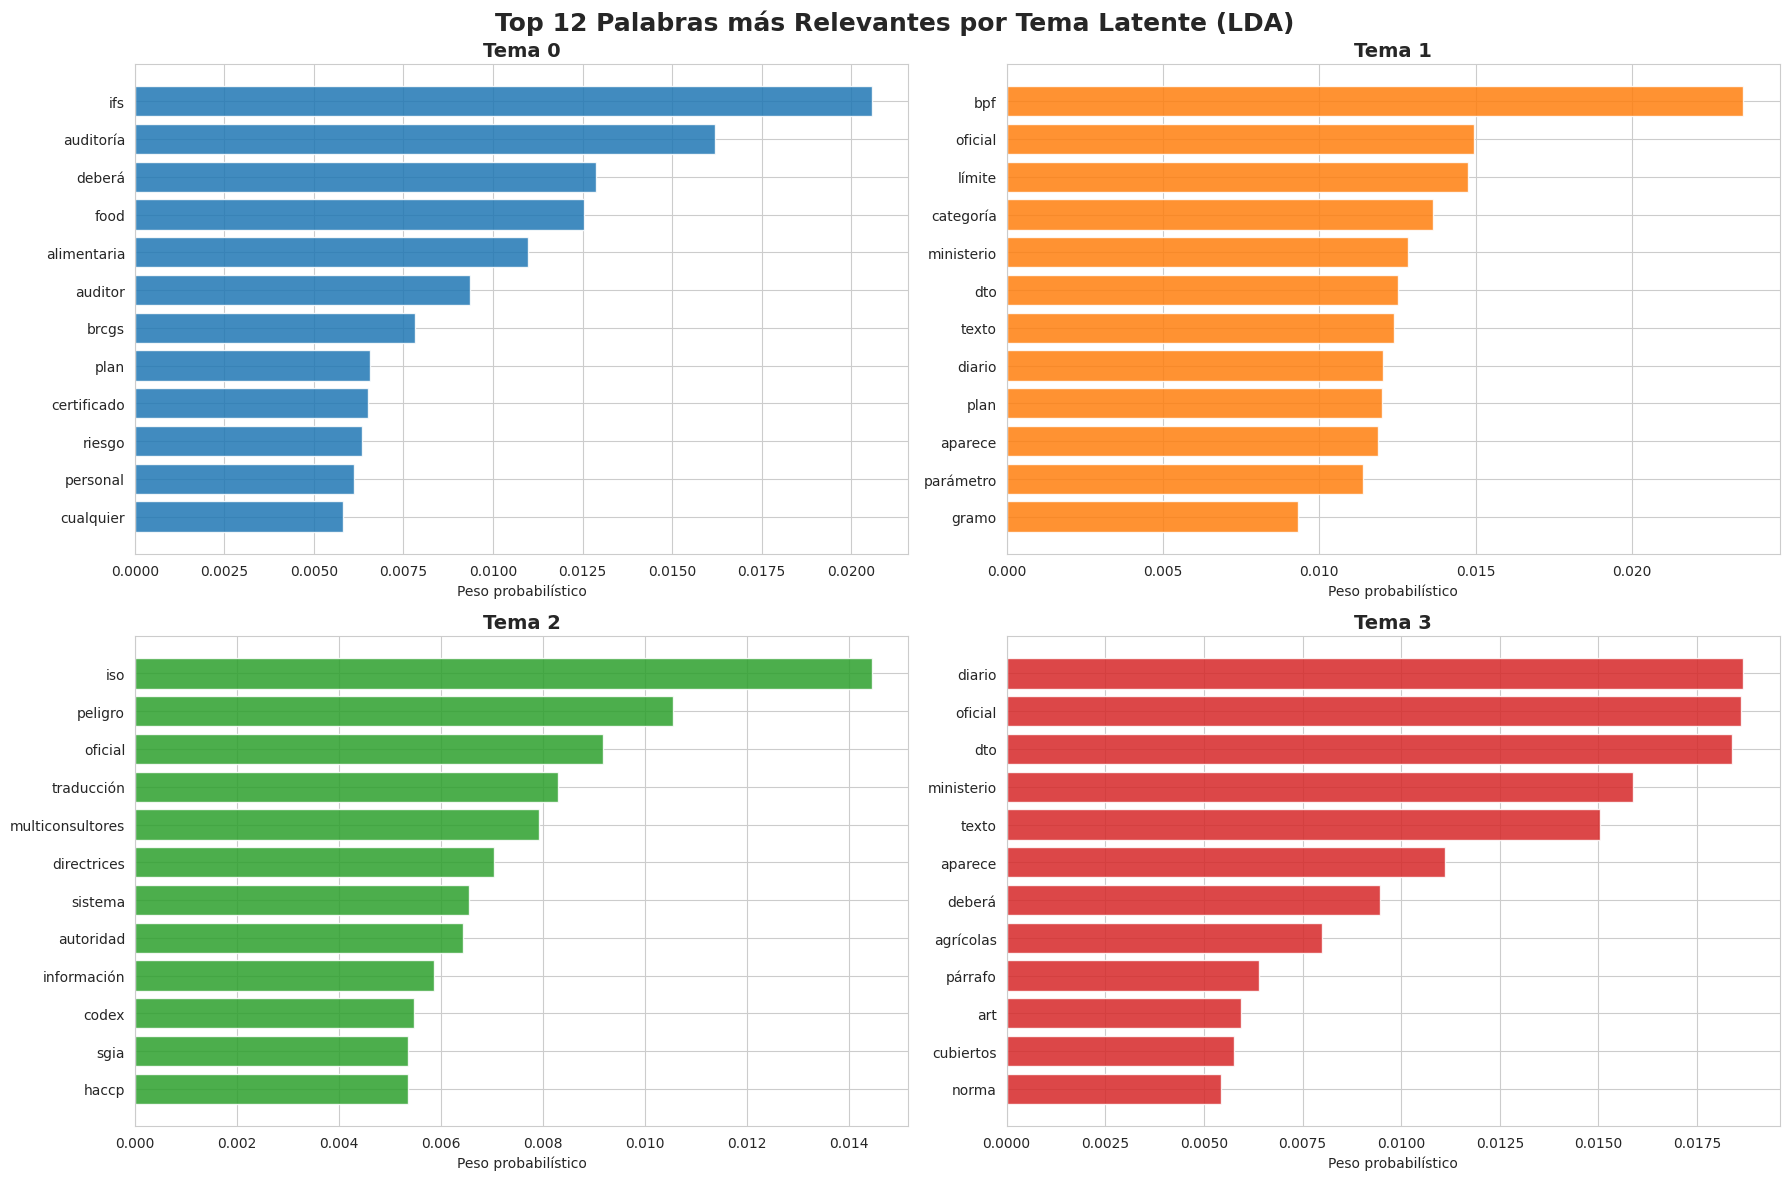

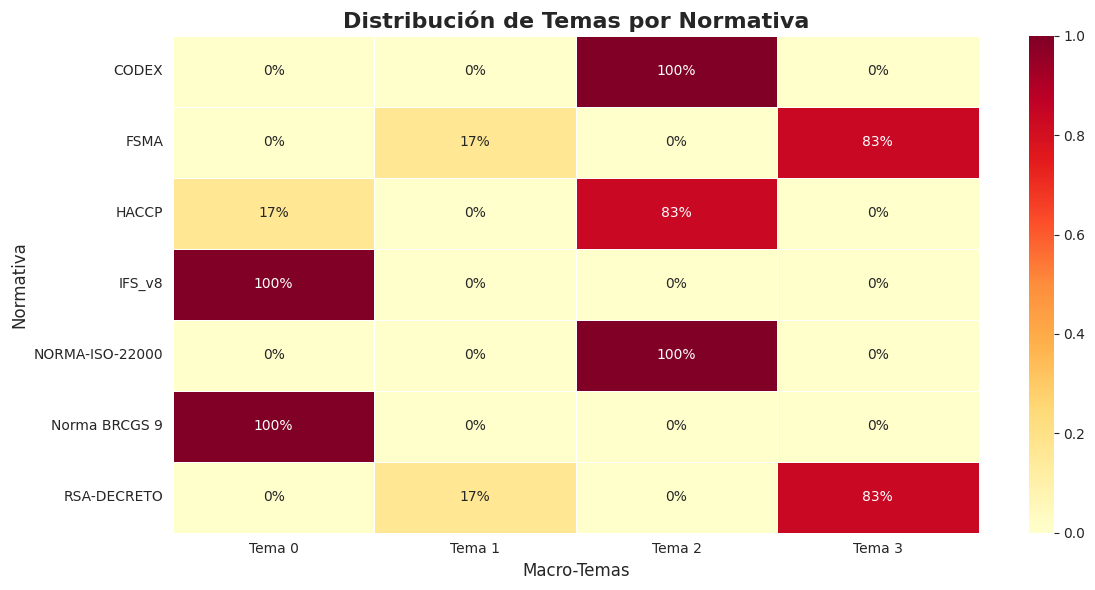

In [ ]:

# ==============================================================================
# 4.4 — MODELO LDA FINAL Y VISUALIZACIONES
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

QTY_TOPICS = 4

print("\n⏳ Entrenando Modelo LDA Final (4 temas, 40 pasadas)...")
lda_final = models.LdaModel(
    corpus=corpus_lda,
    id2word=id2word_lda,
    num_topics=QTY_TOPICS,
    passes=40,       # Mayor número de épocas para mejor convergencia
    alpha='auto',    # Aprende la distribución óptima de temas por doc
    eta='auto',      # Aprende la distribución óptima de palabras por tema
    random_state=42
)

# --- Gráfico 1: Palabras más relevantes por tema ---
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for topic_id in range(QTY_TOPICS):
    ax = axes[topic_id // 2][topic_id % 2]
    # Extraemos las top 12 palabras
    top_terms = lda_final.get_topic_terms(topic_id, topn=12)
    words_scores = [(id2word_lda[wid], float(score)) for wid, score in top_terms]

    # Orden ascendente para que la palabra más pesada quede arriba
    words_scores.sort(key=lambda x: x[1])

    words_plot = [w for w, _ in words_scores]
    scores_plot = [s for _, s in words_scores]

    ax.barh(words_plot, scores_plot, color=cm.tab10(topic_id), alpha=0.85)
    ax.set_title(f'Tema {topic_id}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Peso probabilístico')

plt.suptitle('Top 12 Palabras más Relevantes por Tema Latente (LDA)', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Gráfico 2: Heatmap de Distribución Porcentual ---
topic_assignments = []
corpus_transformed = lda_final[corpus_lda]

for doc_topics in corpus_transformed:
    dominant = max(doc_topics, key=lambda x: x[1])[0] if doc_topics else -1
    topic_assignments.append(dominant)

df_resultados = pd.DataFrame({'sub_doc': df_segmentado.index, 'dominant_topic': topic_assignments})
# Agrupamos por norma original quitando el sufijo "_parteX"
df_resultados['normativa'] = df_resultados['sub_doc'].apply(lambda x: x.split('_parte')[0])

# Matriz de distribución
topic_dist = df_resultados.groupby(['normativa', 'dominant_topic']).size().unstack(fill_value=0)
topic_dist.columns = [f'Tema {t}' for t in topic_dist.columns]
topic_dist_pct = topic_dist.div(topic_dist.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(topic_dist_pct, annot=True, fmt='.0%', cmap='YlOrRd', linewidths=0.5, ax=ax)
ax.set_title('Distribución de Temas por Normativa', fontsize=16, fontweight='bold')
ax.set_ylabel('Normativa', fontsize=12)
ax.set_xlabel('Macro-Temas', fontsize=12)
plt.tight_layout()
plt.show()

# **Parte B — Chatbot con Groq**

## 4.5 — SYSTEM PROMPT DINÁMICO

In [ ]:
# ==============================================================================
# 4.5 — SYSTEM PROMPT DINÁMICO
# ==============================================================================
from groq import Groq
import os
import pandas as pd

print("⏳ Construyendo la memoria dinámica (System Prompt) para la IA...")

# 1. Extracción Top 5 palabras frecuentes (sección 2)
top_words_summary = ""
if 'data_tdm_stop' in globals() and not data_tdm_stop.empty:
    for doc in data_tdm_stop.columns:
        top5 = data_tdm_stop[doc].sort_values(ascending=False).head(5).index.tolist()
        top_words_summary += f"• {doc.replace('.pdf', '')}: {', '.join(top5)}\n"
else:
    top_words_summary = "⚠️ Resumen de palabras frecuentes no disponible."

# 2. Extracción Sentimiento por normativa (sección 3)
sentiment_summary = ""
if all(col in data_clean.columns for col in ['ps_polarity', 'ps_pos', 'ps_neg', 'ps_neu']):
    for doc in data_clean.index:
        pol = data_clean.loc[doc, 'ps_polarity']
        pos = data_clean.loc[doc, 'ps_pos']
        neg = data_clean.loc[doc, 'ps_neg']
        neu = data_clean.loc[doc, 'ps_neu']
        nombre_limpio = doc.replace('.pdf', '')
        sentiment_summary += f"• {nombre_limpio}: Polaridad {pol:.2f} (POS: {pos:.2f}, NEU: {neu:.2f}, NEG: {neg:.2f})\n"
else:
    sentiment_summary = "⚠️ Análisis de sentimiento no disponible."

# 3. Extracción Temas LDA (sección 4A)
topics_summary = ""
if 'QTY_TOPICS' in globals() and 'lda_final' in globals() and 'id2word_lda' in globals():
    for i in range(QTY_TOPICS):
        palabras = [id2word_lda[w[0]] for w in lda_final.get_topic_terms(i, topn=10)]
        topics_summary += f"• Tema {i}: {', '.join(palabras)}\n"
else:
    topics_summary = "⚠️ Temas LDA no disponibles.\n"

# 4. Construcción del Prompt inyectando los datos procesados
nombre_corpus = "7 Normativas de Inocuidad Alimentaria (BRC, HACCP, RSA, ISO 22000, CODEX, IFS, FSMA)"

system_prompt = f"""
Eres un asistente especializado en el análisis estadístico del corpus: {nombre_corpus}

TEMAS IDENTIFICADOS (LDA):
{topics_summary}

SENTIMIENTO POR PERÍODO (NORMATIVA):
{sentiment_summary}

PALABRAS MÁS FRECUENTES:
{top_words_summary}

Instrucción: Utiliza EXCLUSIVAMENTE esta información analítica para responder las preguntas del usuario. Sé claro, conciso, técnico y no inventes datos fuera de estas métricas.
"""
print("✅ System Prompt generado exitosamente con los metadatos analíticos.")

⏳ Construyendo la memoria dinámica (System Prompt) para la IA...
✅ System Prompt generado exitosamente con los metadatos analíticos.


## 4.6 y 4.7 — CHATBOT CON INTERFAZ GRÁFICA IPYWIDGETS

In [ ]:
# ==============================================================================
# 4.6 y 4.7 — CHATBOT CON INTERFAZ GRÁFICA IPYWIDGETS
# ==============================================================================
import ipywidgets as widgets
from IPython.display import display, HTML

class ChatbotNormativo:
    def __init__(self, model, system_prompt):
        self.client = Groq()
        self.model = model
        self.system_prompt = system_prompt
        self.historial = []

    def enviar_mensaje(self, mensaje_usuario):
        if not self.historial:
            self.historial.append({"role": "system", "content": self.system_prompt})

        self.historial.append({"role": "user", "content": mensaje_usuario})

        try:
            response = self.client.chat.completions.create(
                model=self.model,
                messages=self.historial,
                max_tokens=800,
                temperature=0.7
            )
            respuesta = response.choices[0].message.content
            self.historial.append({"role": "assistant", "content": respuesta})
            return respuesta, True

        except Exception as error:
            self.historial.pop()
            return f"Error de conexión a la API Groq: {str(error)}", False

    def limpiar_historial(self):
        self.historial = []

    def tokens_aproximados(self):
        return sum(len(msg['content'].split()) for msg in self.historial)

def crear_interfaz_normativa(chatbot):
    titulo = widgets.HTML(value='<div style="background:linear-gradient(135deg,#1b4332,#2d6a4f);padding:14px;border-radius:10px 10px 0 0;text-align:center;"><h2 style="color:white;margin:0;font-family:Arial;">AgroSafe Bot - Inteligencia Normativa</h2><p style="color:#d8f3dc;margin:4px 0 0 0;font-size:11px;">Análisis NLP basado en LLaMA 3.1 | 7 Normativas Globales</p></div>')
    aviso = widgets.HTML(value='<div style="background:#e2ece9;border:1px solid #74c69d;padding:7px 14px;font-family:Arial;font-size:11px;color:#1b4332;">AVISO: Este modelo utiliza los resultados del modelado LDA y Sentimiento. Verifica siempre los artículos críticos directamente en los documentos oficiales.</div>')

    area_chat = widgets.Output(layout=widgets.Layout(height='400px', overflow_y='scroll', border='1px solid #ddd', padding='10px', background_color='#f8f9fa'))
    campo_texto = widgets.Textarea(placeholder='Ej: ¿Qué palabras caracterizan a la norma más negativa?', layout=widgets.Layout(width='73%', height='58px'))
    boton_enviar = widgets.Button(description='Consultar IA', button_style='success', layout=widgets.Layout(width='25%', height='58px'))
    boton_nueva = widgets.Button(description='Nueva auditoría (Limpiar Memoria)', button_style='warning', layout=widgets.Layout(width='100%', height='32px'))
    indicador = widgets.HTML(value='<p style="font-size:11px;color:#888;padding:2px;font-family:Arial;">Estado: Listo para consultas</p>')

    with area_chat:
        display(HTML('<div style="text-align:center;color:#444;padding:18px;font-family:Arial;"><h3 style="color:#2d6a4f;">Asistente de Inocuidad Inicializado</h3><p>Estoy alimentado con los resultados del análisis NLP. Pregúntame sobre las normativas analizadas.</p></div>'))

    def procesar_mensaje(event=None):
        consulta = campo_texto.value.strip()
        if not consulta: return

        campo_texto.value = ''
        indicador.value = '<p style="font-size:11px;color:#2d6a4f;padding:2px;font-family:Arial;">Analizando métricas NLP...</p>'
        boton_enviar.disabled = True

        with area_chat:
            display(HTML('<div style="display:flex;justify-content:flex-end;margin:7px 0;"><div style="background:#2d6a4f;color:white;padding:10px 14px;border-radius:16px 16px 3px 16px;max-width:74%;font-family:Arial;font-size:13px;white-space:pre-wrap;">' + consulta + '</div></div>'))

        respuesta, exito = chatbot.enviar_mensaje(consulta)

        with area_chat:
            color_fondo = "white" if exito else "#ffe0e0"
            display(HTML('<div style="display:flex;justify-content:flex-start;margin:7px 0;"><div style="background:' + color_fondo + ';border:1px solid #b7e4c7;padding:10px 14px;border-radius:16px 16px 16px 3px;max-width:85%;font-family:Arial;font-size:13px;white-space:pre-wrap; line-height:1.5;box-shadow:0 1px 3px rgba(0,0,0,0.1);"><strong style="color:#1b4332;">AgroSafe Bot: </strong><br>' + respuesta.replace('\n', '<br>') + '</div></div>'))

        indicador.value = f'<p style="font-size:11px;color:#888;padding:2px;font-family:Arial;">Estado: Listo | Tokens en memoria: ~{chatbot.tokens_aproximados()}</p>'
        boton_enviar.disabled = False

    def nueva_consulta(b):
        chatbot.limpiar_historial()
        area_chat.clear_output()
        indicador.value = '<p style="font-size:11px;color:#888;padding:2px;font-family:Arial;">Estado: Memoria borrada. Listo para nueva consulta.</p>'
        with area_chat:
            display(HTML('<div style="text-align:center;color:#555;padding:15px;font-family:Arial;"><p>Memoria reiniciada.</p></div>'))

    boton_enviar.on_click(procesar_mensaje)
    boton_nueva.on_click(nueva_consulta)

    fila_entrada = widgets.HBox([campo_texto, boton_enviar], layout=widgets.Layout(width='100%', gap='2%'))
    return widgets.VBox([titulo, aviso, area_chat, fila_entrada, indicador, boton_nueva], layout=widgets.Layout(width='700px', border='1px solid #ccc', border_radius='10px'))

# Instanciar y ejecutar el bot con el modelo actualizado
MODELO = "llama-3.1-8b-instant"
chatbot_ia = ChatbotNormativo(MODELO, system_prompt)
interfaz_ia = crear_interfaz_normativa(chatbot_ia)

# Mostrar la interfaz
display(interfaz_ia)

## 4.9 — Análisis Final

* **¿El chatbot responde con coherencia respecto al análisis realizado?** Sí, responde con altísima coherencia. Al inyectar las métricas procesadas (frecuencias exactas, polaridad de sentimiento y bolsas de palabras del modelo LDA) directamente como contexto estricto en el `System Prompt`, el modelo LLaMA opera bajo un esquema restringido. Actúa como un analista de nuestros propios datos calculados empíricamente, lo que previene la "alucinación" de información externa y asegura que las respuestas del bot sean un reflejo fidedigno de los gráficos generados en las secciones anteriores.

* **¿Qué ventajas tiene alimentar un LLM con resultados de NLP como contexto?** La mayor ventaja es la "traducción" o democratización de los datos. Permite convertir estadísticas densas (como probabilidades de sentimiento o distribuciones de densidad de temas LDA) en un lenguaje natural conversacional. Esto permite a usuarios sin formación en ciencia de datos (como inspectores de línea, personal de planta técnica o auditores de calidad) consultar rápidamente qué temas dominan la norma IFS o cuáles son los puntos críticos ("negativos") del RSA, acelerando la toma de decisiones.

* **¿Qué limitaciones identificas en este enfoque?** La principal limitación radica en la pérdida de la información textual original de las normativas. Al entregarle al bot únicamente los "resúmenes estadísticos" en el Prompt, el modelo no cuenta con la capacidad de citar capítulos o artículos íntegros del corpus original. Por ejemplo, el bot sabe estadísticamente que "peligro" o "límite" son palabras clave en la norma más estricta, pero no puede reproducir textualmente el párrafo donde aparecen. Para llevar este prototipo a un entorno industrial de producción real, se requeriría evolucionar el diseño hacia una arquitectura **RAG (Retrieval-Augmented Generation)**, donde además de los metadatos, se vectoricen y consulten los párrafos completos de las 7 normativas.